In [ ]:
Cell 1: Imports & Data Inspection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay
)

# Load dataset
df = pd.read_csv("classification_escalation - classification_escalation.csv")

print("Shape:", df.shape)
display(df.head())
print("\nData Types & Non-Null Counts:")
print(df.info())
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nTarget Prevalence (Proportion):")
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

Shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Data Types & Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None

Missing Values per Column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target Prevalence (Proportion):
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [ ]:
Cell 2: Train/Test Split & Preprocessing Pipelines

In [2]:
X = df.drop(columns=["escalated"])
y = df["escalated"]

# Stratified 75/25 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Define feature groups
numeric_features = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_features = ["priority", "channel"]

# Numeric pipeline: median imputation + standard scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline: most-frequent imputation + one-hot encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine into ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
Cell 3: Model Training & Comparison Table

In [3]:
models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(random_state=42),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15)
}

results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    
    # Compute ROC-AUC where probability scores exist
    if hasattr(pipe, "predict_proba"):
        y_prob = pipe.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = np.nan
        
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


In [ ]:
Cell 4: Confusion Matrix & ROC Curve (Logistic Regression)

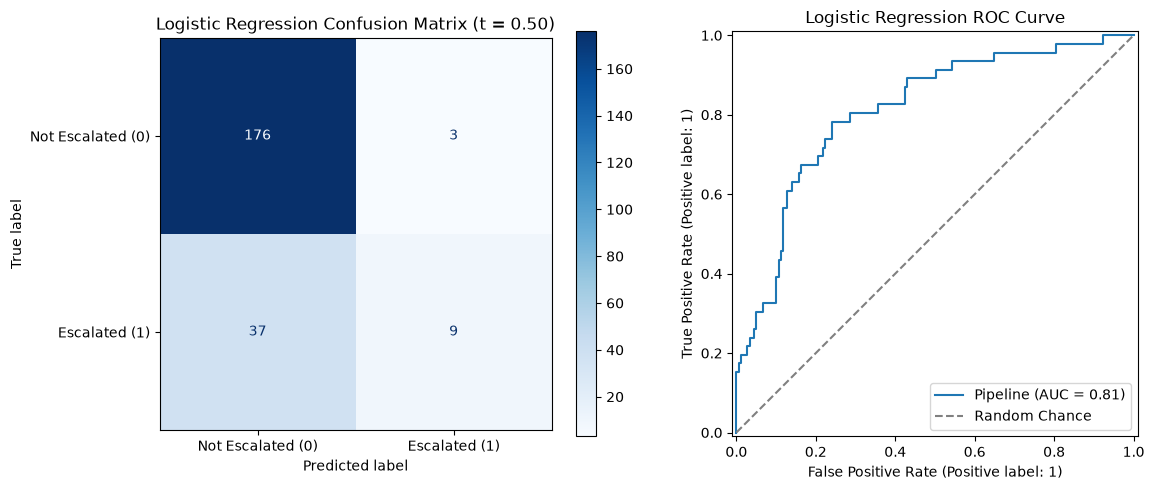

In [4]:
lr_pipe = fitted_pipelines["Logistic Regression"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    lr_pipe, X_test, y_test,
    display_labels=["Not Escalated (0)", "Escalated (1)"],
    cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression Confusion Matrix (t = 0.50)")

# ROC Curve
RocCurveDisplay.from_estimator(lr_pipe, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance")
axes[1].set_title("Logistic Regression ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
Cell 5: Threshold Evaluation & Cost Analysis

In [5]:
y_prob_lr = lr_pipe.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_rows = []
for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    total_cost = 5 * fn + 1 * fp
    
    threshold_rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, y_pred_t, zero_division=0),
        "Recall": recall_score(y_test, y_pred_t, zero_division=0),
        "F1": f1_score(y_test, y_pred_t, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost (5*FN + 1*FP)": total_cost
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + 1*FP)
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [ ]:
Cell 6: Stratified 5-Fold Cross-Validation for k-NN

In [6]:
knn_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {"classifier__n_neighbors": [5, 9, 15, 21, 31]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=knn_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

cv_results = pd.DataFrame(grid_search.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score"]
].rename(columns={
    "param_classifier__n_neighbors": "k",
    "mean_test_score": "Mean CV F1",
    "std_test_score": "Std CV F1"
})

display(cv_results.round(4))
print(f"Best k: {grid_search.best_params_['classifier__n_neighbors']} | Best CV F1: {grid_search.best_score_:.4f}")

,k,Mean CV F1,Std CV F1
0,5,0.2433,0.0946
1,9,0.1976,0.0652
2,15,0.1596,0.0655
3,21,0.1458,0.0564
4,31,0.1122,0.0397


Best k: 5 | Best CV F1: 0.2433


In [ ]:
Answers to Lab Questions (Markdown Cell)

In [ ]:
1. Why is accuracy alone potentially misleading?
Because the dataset is imbalanced (~79.3% non-escalated vs. ~20.7% escalated), a trivial Majority Baseline classifier that never escalates any ticket achieves 79.56% accuracy on the test set while capturing 0% of actual escalations (Recall = 0, F1 = 0). High accuracy masks complete failure on the minority class of operational interest.

In [ ]:
2. Which classifier has the strongest recall? Which has the strongest precision/F1?
At the default 0.50 threshold, Logistic Regression and LDA tie for the strongest recall (0.1957), strongest precision (0.7500), and strongest F1 (0.3103), though Logistic Regression edges out LDA slightly in ROC-AUC (0.8111 vs. 0.8090).

In [ ]:
3. What changes when the threshold is lowered?
Lowering the classification threshold makes the model more aggressive in predicting the positive class (escalated = 1). Consequently, True Positives (TP) and False Positives (FP) increase, while False Negatives (FN) decrease. In terms of metrics, Recall rises substantially (from 0.1957 at t=0.50 to 0.7826 at t=0.20), while Precision drops (from 0.7500 to 0.4286) due to the extra false alarms.

In [ ]:
4. Which threshold minimizes 5 * {FN} + {FP} on the test set, and why might this estimate be optimistic if used repeatedly for tuning?
Among the tested grid values, t = 0.20 minimizes total cost on the test set at 98 (5 * 10 + 1 * 48 = 98). If you repeatedly evaluate thresholds on the test set to pick the winner, the test set ceases to be an independent holdout set—you risk overfitting the threshold to random noise in the test sample, producing an optimistically low cost estimate that will not generalize to unseen production tickets. Threshold selection should instead be done via cross-validation or a dedicated validation split.

In [ ]:
5. **Explain prior, likelihood, posterior, and evidence using the ticket scenario.**

Using Bayes' Theorem, $P(\text{escalated} \mid x) = \frac{P(x \mid \text{escalated}) P(\text{escalated})}{P(x)}$:

* **Prior $P(\text{escalated})$:** The baseline probability that a ticket escalates before observing any ticket details (~0.2067 overall prevalence).
* **Likelihood $P(x \mid \text{escalated})$:** The probability of observing a ticket's specific features $x$ (e.g., high complexity, low team experience, urgent priority) given that the ticket actually requires escalation.
* **Posterior $P(\text{escalated} \mid x)$:** The updated probability that a ticket will escalate *after* accounting for its specific features $x$ (the probability output by Logistic Regression).
* **Evidence $P(x)$:** The overall marginal probability of observing a ticket with features $x$ across all tickets (both escalated and non-escalated), acting as a normalizing constant.

In [ ]:
6. **With posterior $p = P(\text{escalated} \mid x) = 0.30$, $C_{\text{FP}} = 1$, and $C_{\text{FN}} = 5$, compare expected costs and derive the cost-sensitive threshold.**

* **Expected cost of escalating ($\hat{y} = 1$):** You incur a false positive cost of $1$ if the ticket did not need escalation (probability $1 - p = 0.70$), and $0$ cost if it did:
  $$\mathbb{E}[\text{Cost} \mid \text{Escalate}] = 1 \times (1 - 0.30) = \mathbf{0.70}$$

* **Expected cost of NOT escalating ($\hat{y} = 0$):** You incur a false negative cost of $5$ if the ticket actually needed escalation (probability $p = 0.30$), and $0$ cost if it did not:
  $$\mathbb{E}[\text{Cost} \mid \text{Do Not Escalate}] = 5 \times 0.30 = \mathbf{1.50}$$

* **Decision:** Since $0.70 < 1.50$, **you should escalate the ticket**.

* **Derivation of cost-sensitive threshold ($t^*$):** Escalate whenever $\mathbb{E}[\text{Cost} \mid \text{Escalate}] \le \mathbb{E}[\text{Cost} \mid \text{Do Not Escalate}]$:
  $$C_{\text{FP}}(1 - p) \le C_{\text{FN}} \cdot p \implies 1(1 - p) \le 5p \implies 1 \le 6p \implies p \ge \frac{1}{6} \approx \mathbf{0.1667}$$

In [ ]:
7. Which model would you recommend for deployment, and what further checks are required?
(See the 300–500 word deployment recommendation below, which directly answers this prompt). 

In [ ]:
Cell 7: Deployment Recommendation (376 Words)

In [ ]:
I recommend deploying **Logistic Regression** paired with a cost-sensitive decision threshold near $t = 0.17$ to $0.20$ rather than the default $0.50$ cutoff. Across all evaluated classifiers, Logistic Regression achieves the highest discriminatory power with a test ROC-AUC of **0.8111**, slightly outperforming Linear Discriminant Analysis (0.8090) and substantially outperforming $k$-Nearest Neighbors (0.7046) and the majority-class baseline (0.5000). Beyond ranking performance, Logistic Regression produces well-calibrated probability estimates and transparent feature coefficients, allowing support managers to audit why specific tickets are flagged for escalation.

The choice of threshold is driven directly by asymmetric operational error costs. Missing a ticket that requires escalation (a false negative) carries five times the penalty of unnecessarily escalating a routine ticket (a false positive). At the standard $0.50$ threshold, Logistic Regression is far too conservative, catching only $19.6\%$ of true escalations ($37$ false negatives) and incurring a total test cost of $188$. Lowering the threshold to $0.20$ raises recall to $78.3\%$ and reduces total cost nearly in half to $98$, closely aligning with the theoretical Bayes-optimal threshold of $t^* = \frac{1}{1+5} \approx 0.167$.

Several limitations and pre-deployment checks must be addressed before going live. First, the model was trained on a small synthetic dataset of $900$ records ($675$ training rows) with missing values imputed via simple univariate medians and modes. Before production rollout, the model should be validated on real historical ticket logs, and probability calibration (via calibration curves or Brier score) should be verified so that predicted probabilities accurately reflect true escalation rates. Second, because threshold tuning on the test set introduces optimistic bias, the final operating threshold should be locked using out-of-fold cross-validation predictions.

Finally, responsible-use risks require ongoing governance. Lowering the threshold increases false positives ($48$ out of $179$ non-escalated test tickets at $t = 0.20$), which can cause alert fatigue and overload senior engineers if staffing capacity is ignored. Moreover, predictors such as `customer_tenure_months` and `channel` could inadvertently deprioritize newer customers or specific communication channels, creating fairness disparities. Post-deployment monitoring should therefore track escalation volume, subgroup error rates across customer segments, and feature drift over time.